### Figure 1: Motivating examples of threshold and degree distribution combinations.

This code plots the contours of the vulnerable branching ratio $\kappa = 1$ of four combinations of degree and threshold dsitributions:

(a) zeta degrees and Pareto thresholds, 

(b) zeta degrees and truncated Gaussian thresholds,

(c) Poisson degrees and Pareto thresholds,

(d) Poisson degrees and truncated Gaussian thresholds.

Zeta degree distribution and Pareto thresholds are both heterogeneous distributions, but Poisson and Gaussian thresholds are relatively homogeneous. We look at varying degrees of skew in the Pareto threshold distributions.

In [1]:
# Import statements
from figstyle import FIGW_DOUBLE, panel_label, save, COL, LW, REF_COL
from matplotlib.lines import Line2D
from scipy.stats import poisson, norm
from scipy.special import zeta
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt

# Initialize the k grid and values of the exponents
k_grid = np.arange(1, 3001)
k_max = k_grid[-1]
gamma_th_values = [2.05, 2.10, 2.25, 3.00]
colors = COL[:len(gamma_th_values)]
gaussian_width = 0.1

In [2]:
# CDF functions and means
def pareto_tail(gamma_th, phi_bar):
    'Pareto threshold CDF at fraction 1/k, equation 3.'
    scale = k_grid * phi_bar * (gamma_th - 2) / (gamma_th - 1)
    return np.where(scale < 1, 1 - scale ** (gamma_th - 1), 0.0) # cutoff below xmin

def gaussian_tail(mu):
    'Truncated-Gaussian threshold CDF at 1/k plus F(0), equation 5.'
    lower = norm.cdf(-mu / gaussian_width)
    upper = norm.cdf((1 - mu) / gaussian_width)
    cdf = (norm.cdf((1 / k_grid - mu) / gaussian_width) - lower) / (upper - lower)
    f_zero = norm.pdf(-mu / gaussian_width) / (gaussian_width * (upper - lower)) # F(0) is non-zero, so add to truncate properly.
    return cdf, f_zero

def gaussian_mean(mu):
    'Mean of the truncated Gaussian as a function of its location mu, equation 6.'
    lower = norm.cdf(-mu / gaussian_width)
    upper = norm.cdf((1 - mu) / gaussian_width)
    shift = norm.pdf(-mu / gaussian_width) - norm.pdf((1 - mu) / gaussian_width)
    return mu + gaussian_width * shift / (upper - lower)

def crossing_point(f, lo, hi):
    'To find kappa=1 numerically, the root of f(x) = 1 for decreasing f.'
    if f(hi) >= 1:
        return hi
    if f(lo) < 1:
        return np.nan
    return brentq(lambda x: f(x) - 1, lo, hi, xtol=1e-9)

# The mean degree of zeta distribution
zeta_mean = lambda gamma_d: zeta(gamma_d - 1) / zeta(gamma_d)

# GCC formation threshold (condition that <k(k-1)>/<k> > 1)

gamma_d_star = brentq(lambda g: zeta(g - 2) - 2 * zeta(g - 1), 3.01, 6)
gamma_d_grid = np.linspace(2.02, gamma_d_star, 6000) # For plotting, end array at gamma_d_star
z_of_gamma = zeta_mean(gamma_d_grid) # find z at gamma_d for plotting

# Initialize the mean degree arrays
z_values_zeta = np.linspace(zeta_mean(gamma_d_star) + 1e-8, 8, 400)
z_values_poisson = np.linspace(1, 8, 400)

# Map target Gaussian mu to phi 
mu_grid = np.linspace(-0.3, 1.3, 20001)
mean_of_mu = gaussian_mean(mu_grid)


def degree_weights(kind, z):
    'Compute the inner summand value k(k-1) p_k for Poisson or Zeta p_k.'
    if kind == 'poisson':
        return k_grid * (k_grid - 1) * poisson.pmf(k_grid, z)
    gamma_d = np.interp(z, z_of_gamma[::-1], gamma_d_grid[::-1])
    return k_grid * (k_grid - 1) * k_grid ** (-gamma_d) / zeta(gamma_d)


def zeta_tail_terms(kind, z):
    'Tail contribution beyond k_max for zeta degrees; zero for Poisson.'
    if kind == 'poisson':
        return lambda f_zero: 0.0
    gamma_d = np.interp(z, z_of_gamma[::-1], gamma_d_grid[::-1])
    tail = zeta(gamma_d - 1, k_max + 1) - zeta(gamma_d, k_max + 1)
    return lambda f_zero: f_zero * tail / zeta(gamma_d)


def cascade_curve(kind, threshold, gamma_th=None):
    'Solve kappa(z, phi_bar) = 1 for phi_bar at each mean degree z.'
    z_values = z_values_zeta if kind == 'zeta' else z_values_poisson
    phi_bar_values = []

    # Iterate all mean degrees and build the sum according to what distribution it is.
    for z in z_values:

        weight = degree_weights(kind, z) / z

        if threshold == 'pareto':
            phi_bar_values.append(
                crossing_point(lambda p: weight @ pareto_tail(gamma_th, p), 3e-3, 1.0)
            )
        else:
            tail = zeta_tail_terms(kind, z)
            
            # Define the vulnerable branching ratio kappa and solve.
            def kappa(phi_bar):
                mu = np.interp(phi_bar, mean_of_mu, mu_grid)
                cdf, f_zero = gaussian_tail(mu)
                return weight @ cdf + tail(f_zero) / z

            phi_bar_values.append(crossing_point(kappa, 0.02, 1.0))
    return z_values, np.array(phi_bar_values)

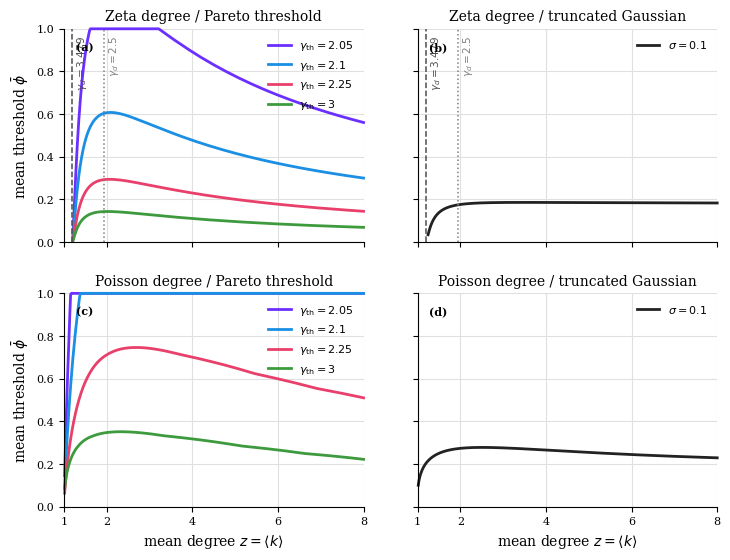

In [3]:
# Name the panel labels and titles
panels = [
    ('a', 'zeta',    'pareto',   'Zeta degree / Pareto threshold'),
    ('b', 'zeta',    'gaussian', 'Zeta degree / truncated Gaussian'),
    ('c', 'poisson', 'pareto',   'Poisson degree / Pareto threshold'),
    ('d', 'poisson', 'gaussian', 'Poisson degree / truncated Gaussian'),
]


fig, axes = plt.subplots(2, 2, figsize=(FIGW_DOUBLE, 5.8), sharex=True, sharey=True)
fig.subplots_adjust(left=0.086, right=0.981, bottom=0.098, top=0.922, wspace=0.18, hspace=0.24)

# Plotting of the four cases.

for ax, (label, kind, threshold, title) in zip(axes.flat, panels):
    if threshold == 'pareto':
        for gamma_th, color in zip(gamma_th_values, colors):
            x, y = cascade_curve(kind, threshold, gamma_th)
            ax.plot(x, y, color=color, lw=LW, clip_on=False)
        handles = [
            Line2D([0], [0], color=color, lw=LW, label=rf'$\gamma_{{\rm th}}={gamma_th:g}$')
            for gamma_th, color in zip(gamma_th_values, colors)
        ]
    else:
        x, y = cascade_curve(kind, threshold)
        ax.plot(x, y, color=REF_COL, lw=LW, clip_on=False)
        handles = [Line2D([0], [0], color=REF_COL, lw=LW, label=r'$\sigma=0.1$')]

    if kind == 'zeta':
        markers = [
            (zeta_mean(gamma_d_star), '--', '0.3', r'$\gamma_d=3.479$'),
            (zeta_mean(2.5), ':', '0.5', r'$\gamma_d=2.5$'),
        ]
        for xline, linestyle, color, text in markers:
            ax.axvline(xline, color=color, ls=linestyle, lw=1.1)
            ax.text(xline + 0.07, 0.97, text, rotation=90, ha='left', va='top',
                    fontsize=7.5, color=color)

    ax.set_xlim(1, 8)
    ax.set_ylim(0, 1)
    ax.set_xticks([1, 2, 4, 6, 8])
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    ax.set_title(title)
    panel_label(ax, label)
    ax.legend(handles=handles, loc='upper right', frameon=False)

# Labelling the outer axes.
for ax in axes[:, 0]:
    ax.set_ylabel(r'mean threshold $\bar{\phi}$')
for ax in axes[1]:
    ax.set_xlabel(r'mean degree $z=\langle k\rangle$')
for ax in axes.flat:
    ax.label_outer()

save(fig, 'figure1')

Below, we run some numerical checks.

In [ ]:
# We check that gamma_d_star is indeed the correct boundary and print what it is
assert abs(zeta(gamma_d_star - 2) - 2 * zeta(gamma_d_star - 1)) < 1e-9, "stated gamma_d_star is not the GCC boundary"
print(f"gamma_d_star = {gamma_d_star:.6f}")

# We check that the map from z -> gamma_d -> z is bijective, effectively
for z in z_values_zeta[::50]:
    gamma_d = np.interp(z, z_of_gamma[::-1], gamma_d_grid[::-1])
    assert abs(zeta_mean(gamma_d) - z) < 1e-2, f"zeta mapping failed at z={z}: {zeta_mean(gamma_d):.4f}"
print("zeta mapping is ok")

# We check that the kappa=1 boundary for Pareto threshold is indeed at 1
for kind in ('zeta', 'poisson'):
    for gamma_th in gamma_th_values:
        z_values, phi_bar_values = cascade_curve(kind, 'pareto', gamma_th)
        for z, phi_bar in zip(z_values, phi_bar_values):
            if np.isnan(phi_bar) or phi_bar >= 1.0:
                continue
            kappa_at_solution = (degree_weights(kind, z) / z) @ pareto_tail(gamma_th, phi_bar)
            assert abs(kappa_at_solution - 1) < 1e-3, f"kappa({kind},pareto,g={gamma_th})={kappa_at_solution:.5f} at z={z}"
print("Pareto curves satisfy kappa = 1")

# We check that the kappa=1 boundary for Gaussian threshold is indeed at 1
for kind in ('zeta', 'poisson'):
    z_values, phi_bar_values = cascade_curve(kind, 'gaussian')
    for z, phi_bar in zip(z_values, phi_bar_values):
        if np.isnan(phi_bar):
            continue
        mu = np.interp(phi_bar, mean_of_mu, mu_grid)
        cdf, f_zero = gaussian_tail(mu)
        kappa_at_solution = (degree_weights(kind, z) / z) @ cdf + zeta_tail_terms(kind, z)(f_zero) / z
        assert abs(kappa_at_solution - 1) < 1e-3, f"kappa({kind},gaussian)={kappa_at_solution:.5f} at z={z}"
print("Gaussian curves satisfy kappa = 1")

gamma_d_star = 3.478751
zeta mapping is ok
Pareto curves satisfy kappa = 1
Gaussian curves satisfy kappa = 1
